# Ethiopian Crop Recommendation Based on Soil and Climate Conditions
**Implementation notebook — eight project tasks** (runs locally from the project folder, or in Google Colab)

This notebook uses the supplied `Crop_recommendation_Ethio.csv` dataset. It predicts crop labels from N, P, K, temperature, humidity, pH, and rainfall and returns the top three model-scored recommendations.

> **Dataset origin (read this first).** The 600-row CSV was supplied to the group without documentation: no author, collection site, dates, measurement units or labelling protocol accompanies it. Its statistical structure (checked in Task 3) is what simulation from crop-specific normal distributions would produce, and is unlike what field measurements typically show, so we treat the rows as **synthetic**. That is an inference from the data, not a documented fact: who generated the file, with what code, and from which crop profiles is not known. The crop names and file name suggest an Ethiopian focus, but there is no evidence that any row is an Ethiopian field observation, and this project must not be described as validated on Ethiopian field data.

**How to run.** *Locally:* `pip install -r requirements.txt`, then open this notebook from the project folder and run all cells (the CSV is read from `data/`). *Colab:* upload this notebook, run all cells, and upload the CSV when prompted. Every figure and table is written to `outputs/`; the model and metadata are written next to the notebook.

## Task 1 — Problem refinement
Build a multiclass classifier that maps seven soil/climate inputs to a crop label. The user-facing output is the three highest-scoring crop classes. Scores are model probabilities, not guaranteed yield or agronomic success.

In [1]:
# Only needed in Google Colab. Locally, use: pip install -r requirements.txt
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install",
                    "scikit-learn", "pandas", "numpy", "matplotlib", "seaborn", "joblib", "scipy"], check=True)

In [2]:
import os, sys, json, zipfile, warnings, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    top_k_accuracy_score, classification_report, confusion_matrix
)
RANDOM_STATE = 42
FEATURES = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
TARGET = "label"

IN_COLAB = "google.colab" in sys.modules
ROOT = Path.cwd()
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "font.size": 12, "axes.titlesize": 13,
                     "axes.labelsize": 12, "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 11})

def savefig(name):
    plt.savefig(OUT / name, dpi=150, bbox_inches="tight")

print(f"Python {platform.python_version()} | scikit-learn {sklearn.__version__} | pandas {pd.__version__} | numpy {np.__version__}")

Python 3.14.6 | scikit-learn 1.9.1 | pandas 3.0.6 | numpy 2.5.3


## Task 2 — Define the AI solution
Compare a majority-class baseline, Decision Tree, Random Forest, and Gradient Boosting. Select the model using validation Macro-F1, then refit it on train + validation data before the final test evaluation.

The next cell writes `input_checks.py`, a small helper used later (and by the Streamlit app) to warn when an input is unfamiliar to the model. In Colab it creates the file; locally it rewrites the identical file that ships with the project.

In [3]:
%%writefile input_checks.py
"""Input-familiarity checks shared by the Streamlit app, the notebook and the tests.

A number can be a *valid* input (finite, pH between 0 and 14, humidity between 0 and 100)
and still be an *unreliable* input, because the model only learned from rows that fall
inside a limited region of feature space.  Two kinds of check are made:

1. Per-feature range check  - is each value inside the range seen when the model was fitted?
2. Combination check        - even if every value is individually in range, is the combination
                              close to at least one fitted row?  (nearest-neighbour distance in
                              standardised feature space, calibrated on the fitted rows themselves)

The thresholds are stored in model_metadata.json by the notebook, so they always describe the
same rows that the saved model was fitted on.
"""
from __future__ import annotations

from dataclasses import dataclass
from typing import Iterable, Mapping

import numpy as np
import pandas as pd

FEATURES = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]

# Severity order: higher = worse.
LEVELS = {"familiar": 0, "edge": 1, "unreliable": 2}


@dataclass(frozen=True)
class Finding:
    level: str            # "edge" or "unreliable"
    kind: str             # "outside_range", "edge_of_range" or "unfamiliar_combination"
    feature: str | None   # None for the combination check
    message: str


def build_reference(X_fit: pd.DataFrame, features: Iterable[str] = FEATURES) -> dict:
    """Summarise the rows the model was fitted on (ranges + nearest-neighbour calibration)."""
    features = list(features)
    X = X_fit[features].astype(float)
    mean, std = X.mean(), X.std(ddof=0).replace(0, 1.0)
    Z = ((X - mean) / std).to_numpy()
    d = np.linalg.norm(Z[:, None, :] - Z[None, :, :], axis=2)
    np.fill_diagonal(d, np.inf)                 # leave-one-out: a row is not its own neighbour
    nn = d.min(axis=1)
    return {
        "fitted_rows": int(len(X)),
        "feature_ranges": {
            f: {"min": float(X[f].min()), "max": float(X[f].max()),
                "p01": float(X[f].quantile(0.01)), "p99": float(X[f].quantile(0.99))}
            for f in features
        },
        "scaler": {"mean": {f: float(mean[f]) for f in features},
                   "std": {f: float(std[f]) for f in features}},
        "novelty_check": {
            "method": "distance to nearest fitted row in standardised feature space (leave-one-out calibration)",
            "threshold_p99": float(np.percentile(nn, 99)),
            "loo_distance_percentiles": {str(p): float(np.percentile(nn, p)) for p in (50, 90, 95, 99, 100)},
        },
    }


def nearest_distance(values: Mapping[str, float], reference: Mapping, fitted_features: pd.DataFrame) -> float:
    """Distance from one input to its nearest fitted row (standardised units)."""
    feats = list(reference["feature_ranges"])
    mean, std = reference["scaler"]["mean"], reference["scaler"]["std"]
    z = np.array([(float(values[f]) - mean[f]) / std[f] for f in feats])
    Z = ((fitted_features[feats].astype(float) - pd.Series(mean)) / pd.Series(std)).to_numpy()
    return float(np.linalg.norm(Z - z, axis=1).min())


def assess_inputs(values: Mapping[str, float], reference: Mapping,
                  fitted_features: pd.DataFrame | None = None,
                  labels: Mapping[str, str] | None = None) -> list[Finding]:
    """Return a list of findings (empty list = every value looks familiar to the model)."""
    labels = labels or {}
    findings: list[Finding] = []
    outside_any = False
    for f, r in reference["feature_ranges"].items():
        v, name = float(values[f]), labels.get(f, f)
        lo, hi = r["min"], r["max"]
        if v < lo or v > hi:
            outside_any = True
            findings.append(Finding(
                "unreliable", "outside_range", f,
                f"{name} = {v:g} is outside the range the model was fitted on ({lo:.4g} to {hi:.4g}). "
                "The model has never seen a value like this, so its ranking is an extrapolation."))
        elif v < r["p01"] or v > r["p99"]:
            findings.append(Finding(
                "edge", "edge_of_range", f,
                f"{name} = {v:g} is at the extreme edge of the fitted range ({lo:.4g} to {hi:.4g}); "
                "fewer than 1 in 100 fitted rows are this extreme."))
    if fitted_features is not None and not outside_any:
        dist = nearest_distance(values, reference, fitted_features)
        thr = reference["novelty_check"]["threshold_p99"]
        if dist > thr:
            findings.append(Finding(
                "unreliable", "unfamiliar_combination", None,
                "Each value is individually within the fitted range, but this combination of values is unlike "
                f"any row the model was fitted on (distance {dist:.2f} vs. {thr:.2f} for the most unusual 1% of "
                "fitted rows)."))
    return findings


def overall_level(findings: list[Finding]) -> str:
    """'familiar', 'edge' or 'unreliable' - the worst level among the findings."""
    worst = "familiar"
    for f in findings:
        if LEVELS[f.level] > LEVELS[worst]:
            worst = f.level
    return worst

Overwriting input_checks.py


## Task 3 — Load and prepare data

**What preparation does and does not do.** Preparation validates the file: it keeps the seven feature columns and the label, converts features to numbers, trims and lower-cases labels, and drops rows with missing or non-finite values. **We did not generate, augment, oversample or edit any rows.** That statement is only about our own pipeline; it says nothing about how the supplied rows were produced (see the next section).

In [4]:
# Read the CSV from data/ if it is there; otherwise (Colab) ask for an upload.
LOCAL_CSV = ROOT / "data" / "Crop_recommendation_Ethio.csv"
if LOCAL_CSV.exists():
    DATA_PATH = LOCAL_CSV
else:
    from google.colab import files
    uploaded = files.upload()
    csv_files = [name for name in uploaded if name.lower().endswith(".csv")]
    if not csv_files:
        raise FileNotFoundError("Upload the supplied CSV dataset.")
    DATA_PATH = Path(csv_files[0])

raw = pd.read_csv(DATA_PATH)
raw.columns = [str(c).strip() for c in raw.columns]
required = FEATURES + [TARGET]
missing = [c for c in required if c not in raw.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

df = raw[required].copy()
for col in FEATURES:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df[TARGET] = df[TARGET].astype("string").str.strip().str.lower()
df = df.dropna(subset=required)
df = df[np.isfinite(df[FEATURES]).all(axis=1)].copy()
df[TARGET] = df[TARGET].astype(str)

print("Data file:", DATA_PATH.name)
print("Rows in file:", len(raw), "| rows after validation:", len(df), "| rows removed:", len(raw) - len(df),
      "| exact duplicate rows:", int(df.duplicated().sum()))
print("Dataset shape:", df.shape)
print("Crop classes:", sorted(df[TARGET].unique()))
display(df.head())
display(df[FEATURES].describe().T)

Data file: Crop_recommendation_Ethio.csv
Rows in file: 600 | rows after validation: 600 | rows removed: 0 | exact duplicate rows: 0
Dataset shape: (600, 8)
Crop classes: ['barley', 'chickpea', 'coffee', 'enset', 'haricot_bean', 'maize', 'sesame', 'sorghum', 'teff', 'wheat']


,N,P,K,temperature,humidity,ph,rainfall,label
0,57.437737,28.760095,40.253158,21.351412,44.342754,5.844237,667.897656,teff
1,52.470059,34.899193,29.028693,21.198495,63.444544,6.323111,807.813769,teff
2,58.740075,29.844245,37.581255,16.602793,64.149152,6.282526,624.119269,teff
3,49.552564,42.335248,33.918294,17.929180,55.535065,6.486308,701.162169,teff
4,58.301861,37.584926,49.991533,17.983962,54.414301,6.015180,736.237119,teff


,count,mean,std,min,25%,50%,75%,max
N,600.0,57.915625,16.844512,17.974644,44.937117,58.313199,70.876590,96.631881
P,600.0,33.517393,8.014991,11.444717,28.082054,33.185081,38.631341,60.295968
K,600.0,35.811003,8.887101,9.579881,30.340635,35.616907,41.538726,63.225384
temperature,600.0,21.303418,4.096290,10.310659,18.391492,20.850878,24.378382,33.112825
humidity,600.0,59.129900,12.651901,22.461110,49.960554,57.725392,67.714333,100.000000
ph,600.0,6.384012,0.467671,5.098469,6.063829,6.379220,6.698635,8.061117
rainfall,600.0,729.863739,321.918920,100.000000,504.857926,652.741847,875.750746,1742.484500


### Where did the rows come from? Evidence from the data itself
The file has no documentation, so the only evidence available is the data. The checks below are computed from the rows; they do not prove how the file was made, but they are what a simulation from crop-specific normal distributions would leave behind and what real field data usually would not:

1. **Perfectly balanced classes** — real surveys are almost never exactly balanced.
2. **Every class-by-feature distribution is consistent with a normal distribution**, including rainfall, which in field records is usually skewed.
3. **Features are uncorrelated within each crop** — the average absolute within-crop correlation matches what independent random draws would give. Field data normally shows relationships (for example, humidity with rainfall, or N with P and K).
4. **The spread is nearly the same for every crop** while the means differ by a factor of three (rainfall SD is about 130–150 mm-units for all ten crops, whether the mean is 440 or 1,415); in real data variability usually grows with the mean.
5. **Values sit at hard limits and are recorded to ~15 decimal places** — humidity capped at exactly 100 and rainfall floored at exactly 100 are what clipping generated values produces; instrument readings are rounded.

In [5]:
g = df.groupby(TARGET)

# 1. class balance
counts = df[TARGET].value_counts()

# 2. Shapiro-Wilk per class x feature (p > 0.05 = not distinguishable from normal)
shap = pd.DataFrame({f: g[f].apply(lambda s: stats.shapiro(s).pvalue) for f in FEATURES})
share_normal = float((shap > 0.05).to_numpy().mean())

# 3. mean |correlation| between features, within each crop, vs. what independent draws would give
within = np.mean([np.abs(grp[FEATURES].corr().to_numpy()[np.triu_indices(len(FEATURES), 1)]).mean()
                  for _, grp in g])
rng = np.random.default_rng(RANDOM_STATE)
n_per = int(counts.min())
sim = np.mean([np.abs(np.corrcoef(rng.normal(size=(n_per, len(FEATURES))), rowvar=False)
                      [np.triu_indices(len(FEATURES), 1)]).mean() for _ in range(500)])
pooled = np.abs(df[FEATURES].corr().to_numpy()[np.triu_indices(len(FEATURES), 1)]).mean()

# 4. spread vs. mean for rainfall
rain = g["rainfall"].agg(["mean", "std"]); rain["cv_pct"] = 100 * rain["std"] / rain["mean"]

# 5. clipping at hard limits and numeric precision
n_hum100 = int((df["humidity"] >= 100).sum()); n_rain100 = int((df["rainfall"] <= 100).sum())
many_dec = float((np.abs(df[FEATURES] * 1e6 - np.round(df[FEATURES] * 1e6)) > 1e-3).to_numpy().mean())

provenance_checks = pd.DataFrame([
    ("Rows per crop (min / max)", f"{counts.min()} / {counts.max()}", "Exactly balanced"),
    ("Class-by-feature distributions consistent with normal (Shapiro p>0.05)", f"{share_normal:.0%} of {shap.size}", "Expect ~95% if normal; real field data usually fails some"),
    ("Mean |within-crop correlation| between features", f"{within:.3f}", f"Independent draws give ~{sim:.3f}"),
    ("Mean |correlation| across all rows pooled", f"{pooled:.3f}", "Higher only because crops differ in their means"),
    ("Rainfall SD across crops (min / max)", f"{rain['std'].min():.0f} / {rain['std'].max():.0f}", "Near-constant spread"),
    ("Rainfall mean across crops (min / max)", f"{rain['mean'].min():.0f} / {rain['mean'].max():.0f}", "...while the means differ about 3x"),
    ("Rainfall coefficient of variation across crops", f"{rain['cv_pct'].min():.0f}% / {rain['cv_pct'].max():.0f}%", "Real variability usually scales with the mean"),
    ("Rows with humidity at exactly 100 / rainfall at exactly 100", f"{n_hum100} / {n_rain100}", "Signature of clipping generated values at a bound"),
    ("Share of values with more than 6 decimal places", f"{many_dec:.0%}", "Instrument readings are rounded"),
], columns=["check", "result", "how to read it"])
provenance_checks.to_csv(OUT / "data_provenance_checks.csv", index=False)
pd.set_option("display.max_colwidth", 120)
display(provenance_checks)

,check,result,how to read it
0,Rows per crop (min / max),60 / 60,Exactly balanced
1,Class-by-feature distributions consistent with normal (Shapiro p>0.05),100% of 70,Expect ~95% if normal; real field data usually fails some
2,Mean |within-crop correlation| between features,0.100,Independent draws give ~0.104
3,Mean |correlation| across all rows pooled,0.243,Higher only because crops differ in their means
4,Rainfall SD across crops (min / max),131 / 153,Near-constant spread
5,Rainfall mean across crops (min / max),441 / 1415,...while the means differ about 3x
6,Rainfall coefficient of variation across crops,10% / 31%,Real variability usually scales with the mean
7,Rows with humidity at exactly 100 / rainfall at exactly 100,1 / 1,Signature of clipping generated values at a bound
8,Share of values with more than 6 decimal places,100%,Instrument readings are rounded


**Conclusion on provenance (the wording used in the README and report).**

- *Were the records synthetically generated?* The evidence above says almost certainly yes. This is an inference; the file carries no documentation that confirms it.
- *Where did they come from?* They were supplied to the group as a CSV. The author, the generating code, the date, and the crop profiles used are not documented and could not be verified.
- *How were the crop labels assigned?* The structure indicates each row was generated *for* a crop, around a crop-specific profile of nutrient, climate and pH values, so the label is the generating category. It is **not** a recorded outcome such as the crop a farmer grew or the crop that gave the best yield on that plot. Units (for example whether temperature is °C and rainfall is mm) are also undocumented.
- *What this means for the results:* the model is learning to separate ten overlapping generated profiles, so the scores below are software-validation results, not agricultural validation.

## Task 4 — Exploratory data analysis

,count
label,
barley,60
chickpea,60
coffee,60
enset,60
haricot_bean,60
maize,60
sesame,60
sorghum,60
teff,60


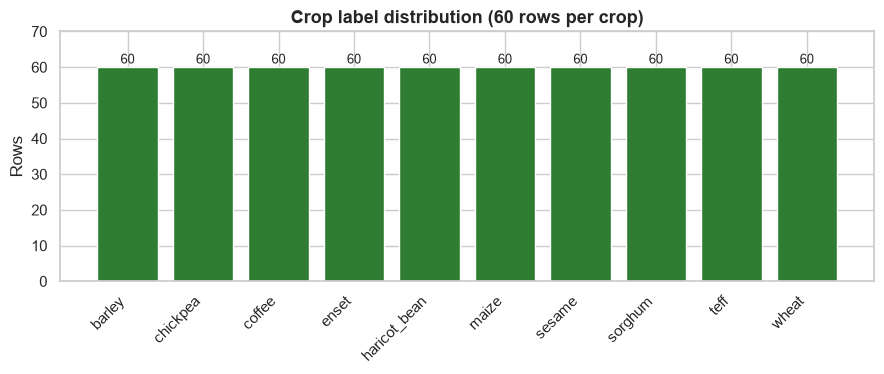

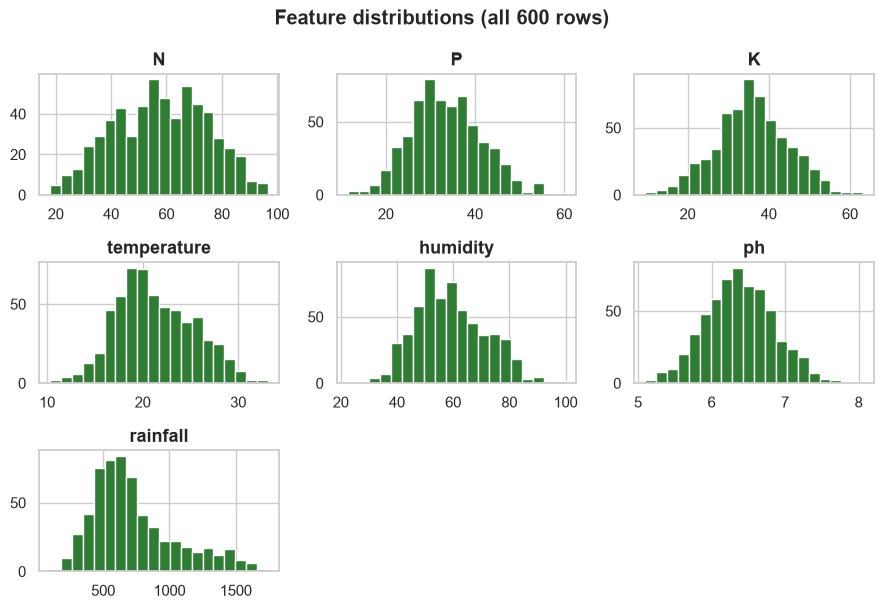

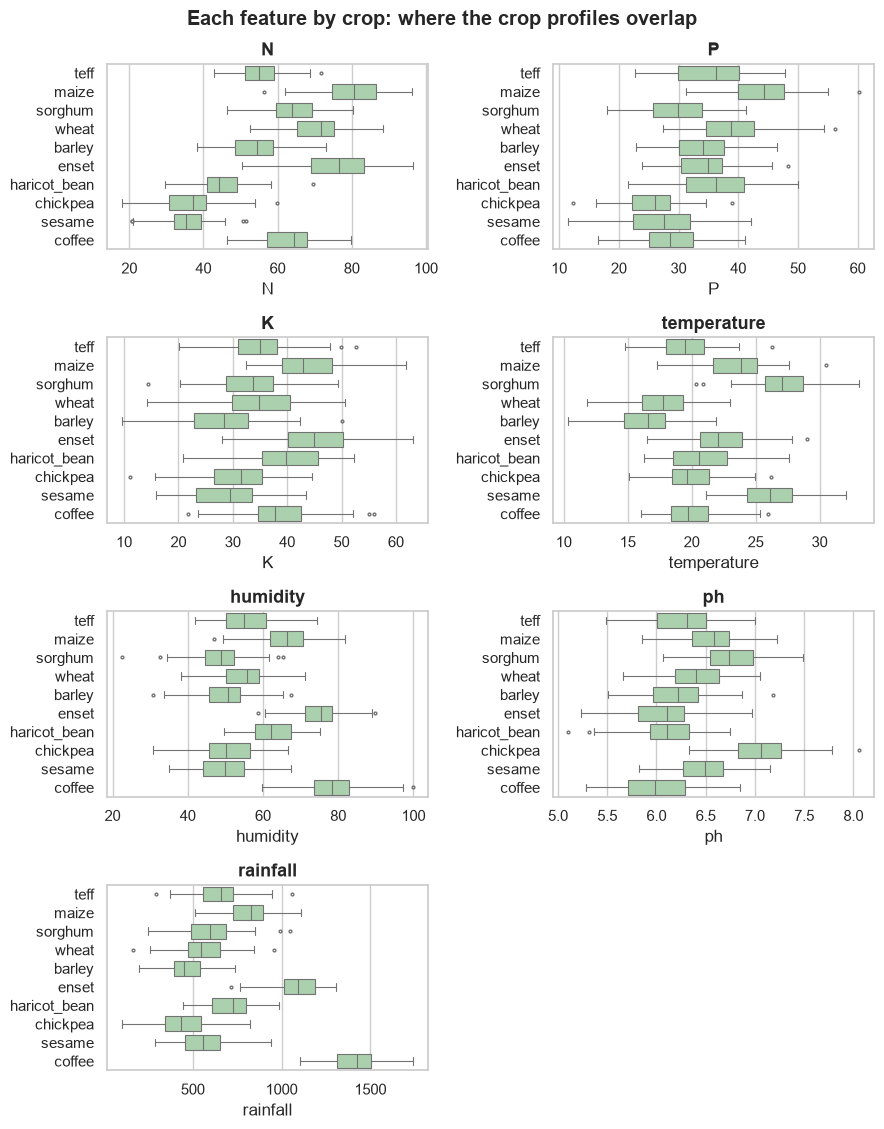

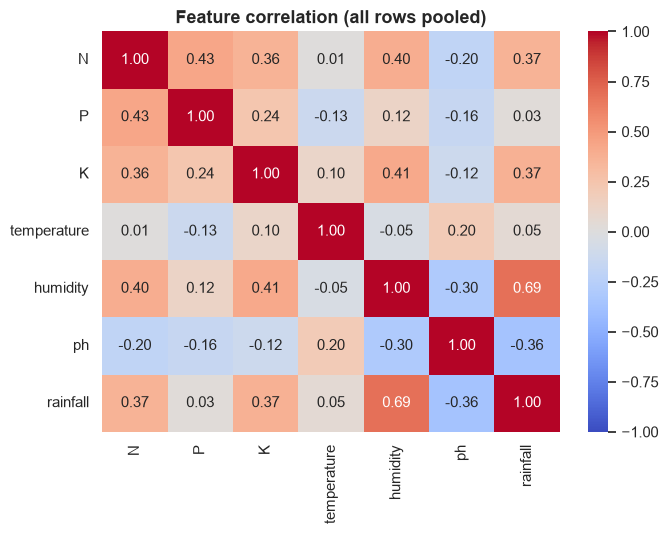

In [6]:
class_counts = df[TARGET].value_counts().rename("count").sort_index()
display(class_counts.to_frame())
class_counts.rename_axis("crop").reset_index().to_csv(OUT / "class_distribution.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 3.9))
ax.bar(class_counts.index, class_counts.values, color="#2E7D32")
ax.set_title("Crop label distribution (60 rows per crop)"); ax.set_ylabel("Rows")
ax.set_ylim(0, 70); plt.xticks(rotation=45, ha="right")
for i, v in enumerate(class_counts.values): ax.text(i, v + 1, str(v), ha="center", fontsize=9)
plt.tight_layout(); savefig("class_distribution.png"); plt.show()

axes = df[FEATURES].hist(figsize=(9, 6.2), bins=20, color="#2E7D32", edgecolor="white")
plt.suptitle("Feature distributions (all 600 rows)", fontweight="bold"); plt.tight_layout()
savefig("feature_histograms.png"); plt.show()

fig, axes = plt.subplots(4, 2, figsize=(9, 11.5))
for ax, f in zip(axes.ravel(), FEATURES):
    sns.boxplot(data=df, y=TARGET, x=f, ax=ax, color="#A5D6A7", fliersize=2, linewidth=0.8)
    ax.set_title(f); ax.set_ylabel("")
axes.ravel()[-1].axis("off")
fig.suptitle("Each feature by crop: where the crop profiles overlap", fontweight="bold")
plt.tight_layout(); savefig("feature_by_crop_boxplots.png"); plt.show()

plt.figure(figsize=(7, 5.5))
sns.heatmap(df[FEATURES].corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, annot_kws={"size": 11})
plt.title("Feature correlation (all rows pooled)"); plt.tight_layout()
savefig("correlation_heatmap.png"); plt.show()

## Task 5 — Build baseline and candidate models

Train=420, validation=90, test=90


,model,validation_accuracy,validation_macro_f1,validation_weighted_f1
2,Random Forest,0.744444,0.746982,0.746982
3,Gradient Boosting,0.677778,0.699174,0.699174
1,Decision Tree,0.611111,0.606294,0.606294
0,Majority baseline,0.100000,0.018182,0.018182


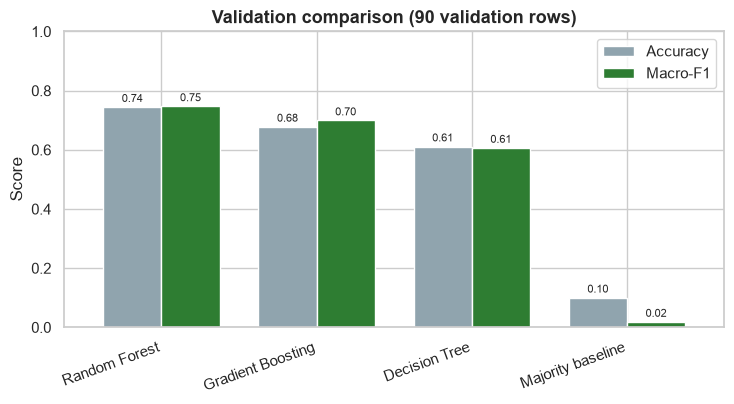

In [7]:
X, y = df[FEATURES], df[TARGET]
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)
print(f"Train={len(X_train)}, validation={len(X_val)}, test={len(X_test)}")

candidates = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE,
                                            class_weight="balanced", n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}
comparison = []
for name, model in candidates.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_val)
    comparison.append({
        "model": name,
        "validation_accuracy": accuracy_score(y_val, pred),
        "validation_macro_f1": f1_score(y_val, pred, average="macro", zero_division=0),
        "validation_weighted_f1": f1_score(y_val, pred, average="weighted", zero_division=0)
    })
comparison_df = pd.DataFrame(comparison).sort_values("validation_macro_f1", ascending=False)
display(comparison_df)
comparison_df.to_csv(OUT / "validation_model_comparison.csv", index=False)

fig, ax = plt.subplots(figsize=(7.5, 4.2))
plot_df = comparison_df.set_index("model")[["validation_accuracy", "validation_macro_f1"]]
plot_df.plot(kind="bar", ax=ax, color=["#90A4AE", "#2E7D32"], width=0.75)
ax.set_title("Validation comparison (90 validation rows)"); ax.set_ylabel("Score"); ax.set_xlabel("")
ax.set_ylim(0, 1.0); ax.legend(["Accuracy", "Macro-F1"]); plt.xticks(rotation=20, ha="right")
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=8, padding=2)
plt.tight_layout(); savefig("validation_model_comparison.png"); plt.show()

## Task 6 — Improve and select the model
Choose by validation Macro-F1, then refit on train + validation. Keep the test split untouched until final evaluation.

In [8]:
best_name = comparison_df.iloc[0]["model"]
best_model = clone(candidates[best_name])
X_trainval = pd.concat([X_train, X_val])
y_trainval = pd.concat([y_train, y_val])
best_model.fit(X_trainval, y_trainval)
print("Selected model:", best_name, "| fitted on", len(X_trainval), "rows (train + validation)")

# SUPPLEMENTARY stability check only: these folds use all 600 rows, including the 90 held-out test rows,
# so this is NOT an independent estimate. The held-out test result in Task 7 is the primary evaluation.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(clone(candidates[best_name]), X, y, cv=cv,
                            scoring="f1_macro", n_jobs=-1)
print(f"5-fold Macro-F1: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")
pd.DataFrame({"fold": range(1, len(cv_scores) + 1), "macro_f1": cv_scores}).to_csv(OUT / "five_fold_cv.csv", index=False)

Selected model: Random Forest | fitted on 510 rows (train + validation)
5-fold Macro-F1: 0.802 ± 0.029


## Task 7 — Evaluate on the held-out test set
Two different questions are answered here, and they should not be confused:

- **Test accuracy** — is the crop with the *single highest* model score the true label?
- **Top-3 accuracy** — is the true label *anywhere among the three* highest-scored crops? This matches what the app shows (three crops), but it is an easier test, and it does not say which of the three is right.

In [9]:
test_pred = best_model.predict(X_test)
test_proba = best_model.predict_proba(X_test)
classes = best_model.classes_
metrics = {
    "selected_model": best_name,
    "test_rows": len(y_test),
    "accuracy": accuracy_score(y_test, test_pred),
    "macro_precision": precision_score(y_test, test_pred, average="macro", zero_division=0),
    "macro_recall": recall_score(y_test, test_pred, average="macro", zero_division=0),
    "macro_f1": f1_score(y_test, test_pred, average="macro", zero_division=0),
    "weighted_f1": f1_score(y_test, test_pred, average="weighted", zero_division=0),
    "top3_accuracy": top_k_accuracy_score(y_test, test_proba, k=min(3, len(classes)), labels=classes)
}
display(pd.DataFrame([metrics]).T.rename(columns={0: "value"}))
pd.DataFrame([metrics]).to_csv(OUT / "test_metrics.csv", index=False)

report = classification_report(y_test, test_pred, zero_division=0, output_dict=True)
pd.DataFrame(report).T.to_csv(OUT / "classification_report.csv")
print(classification_report(y_test, test_pred, zero_division=0))

,value
selected_model,Random Forest
test_rows,90
accuracy,0.833333
macro_precision,0.836302
macro_recall,0.833333
macro_f1,0.83054
weighted_f1,0.83054
top3_accuracy,0.966667


              precision    recall  f1-score   support

      barley       0.86      0.67      0.75         9
    chickpea       0.80      0.89      0.84         9
      coffee       0.89      0.89      0.89         9
       enset       0.80      0.89      0.84         9
haricot_bean       0.86      0.67      0.75         9
       maize       0.89      0.89      0.89         9
      sesame       0.88      0.78      0.82         9
     sorghum       0.82      1.00      0.90         9
        teff       0.78      0.78      0.78         9
       wheat       0.80      0.89      0.84         9

    accuracy                           0.83        90
   macro avg       0.84      0.83      0.83        90
weighted avg       0.84      0.83      0.83        90



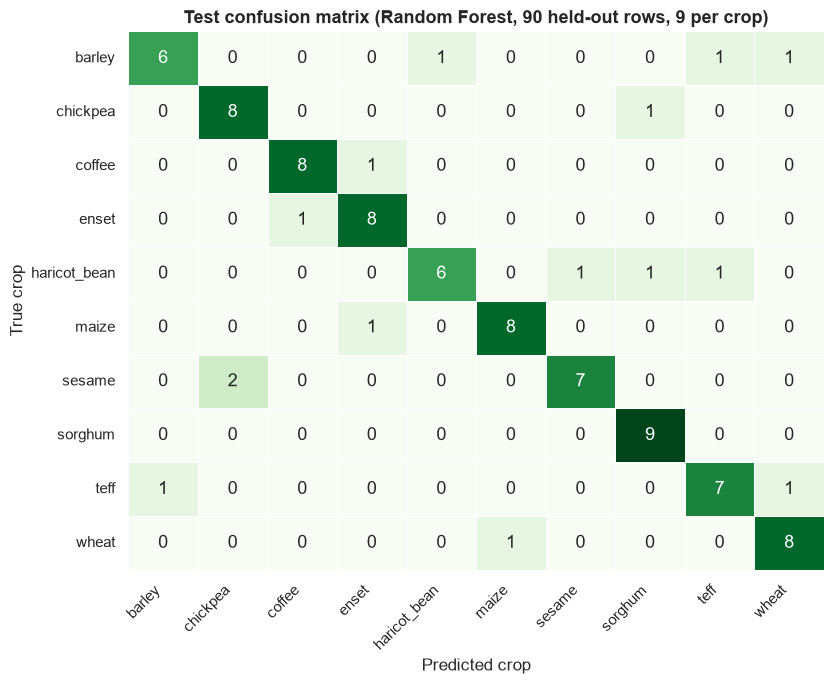

,true_crop,predicted_as,count
0,sesame,chickpea,2
1,barley,haricot_bean,1
2,barley,teff,1
3,barley,wheat,1
4,chickpea,sorghum,1
5,coffee,enset,1
6,enset,coffee,1
7,haricot_bean,sesame,1
8,haricot_bean,sorghum,1
9,haricot_bean,teff,1


,precision,recall,f1-score,support,correct
crop,,,,,
barley,0.857,0.667,0.750,9,6
chickpea,0.800,0.889,0.842,9,8
coffee,0.889,0.889,0.889,9,8
enset,0.800,0.889,0.842,9,8
haricot_bean,0.857,0.667,0.750,9,6
maize,0.889,0.889,0.889,9,8
sesame,0.875,0.778,0.824,9,7
sorghum,0.818,1.000,0.900,9,9
teff,0.778,0.778,0.778,9,7


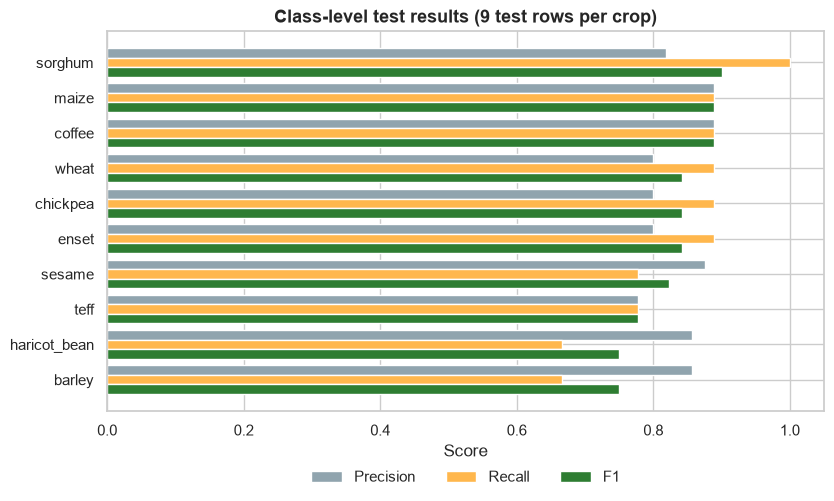

In [10]:
# ---- Confusion matrix (counts) ----
cm = confusion_matrix(y_test, test_pred, labels=classes)
pd.DataFrame(cm, index=classes, columns=classes).to_csv(OUT / "confusion_matrix.csv")

fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(cm, annot=True, annot_kws={"size": 13}, fmt="d", cmap="Greens", cbar=False, linewidths=0.5, linecolor="white",
            xticklabels=classes, yticklabels=classes, ax=ax)
ax.set_xlabel("Predicted crop"); ax.set_ylabel("True crop")
ax.set_title(f"Test confusion matrix ({best_name}, {len(y_test)} held-out rows, 9 per crop)")
plt.xticks(rotation=45, ha="right"); plt.yticks(rotation=0)
plt.tight_layout(); savefig("confusion_matrix.png"); plt.show()

# ---- Which crops get mixed up? ----
pairs = [(classes[i], classes[j], int(cm[i, j])) for i in range(len(classes))
         for j in range(len(classes)) if i != j and cm[i, j] > 0]
top_confusions = (pd.DataFrame(pairs, columns=["true_crop", "predicted_as", "count"])
                  .sort_values(["count", "true_crop"], ascending=[False, True]).reset_index(drop=True))
top_confusions.to_csv(OUT / "top_confusions.csv", index=False)
display(top_confusions)

# ---- Class-level results ----
per_class = pd.DataFrame(report).T.loc[list(classes), ["precision", "recall", "f1-score", "support"]]
per_class["correct"] = np.diag(cm); per_class["support"] = per_class["support"].astype(int)
per_class.index.name = "crop"
per_class.to_csv(OUT / "per_class_metrics.csv")
display(per_class.round(3))

order_by_f1 = per_class.sort_values("f1-score")
fig, ax = plt.subplots(figsize=(8.5, 5.2))
y_pos = np.arange(len(order_by_f1)); h = 0.27
ax.barh(y_pos + h, order_by_f1["precision"], h, label="Precision", color="#90A4AE")
ax.barh(y_pos, order_by_f1["recall"], h, label="Recall", color="#FFB74D")
ax.barh(y_pos - h, order_by_f1["f1-score"], h, label="F1", color="#2E7D32")
ax.set_yticks(y_pos); ax.set_yticklabels(order_by_f1.index); ax.set_xlim(0, 1.05)
ax.set_title("Class-level test results (9 test rows per crop)")
ax.set_xlabel("Score"); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False); plt.tight_layout(); savefig("per_class_metrics.png"); plt.show()

,k,rows_correct,accuracy,random_guess
0,1,75,0.833333,0.1
1,2,85,0.944444,0.2
2,3,87,0.966667,0.3
3,4,88,0.977778,0.4
4,5,89,0.988889,0.5


Top-1 correct: 75/90 | top-3 contains the true crop: 87/90
Of 15 rows where the top choice was wrong, 12 had the true crop as 2nd or 3rd choice and 3 were missed even by the top three.


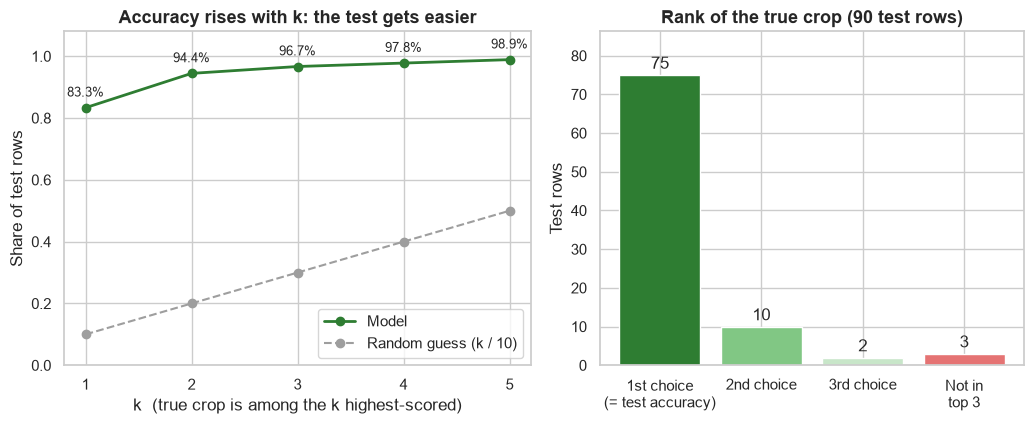

,feature,importance
0,N,0.218859
6,rainfall,0.188440
3,temperature,0.167013
4,humidity,0.125410
5,ph,0.108988
1,P,0.101527
2,K,0.089764


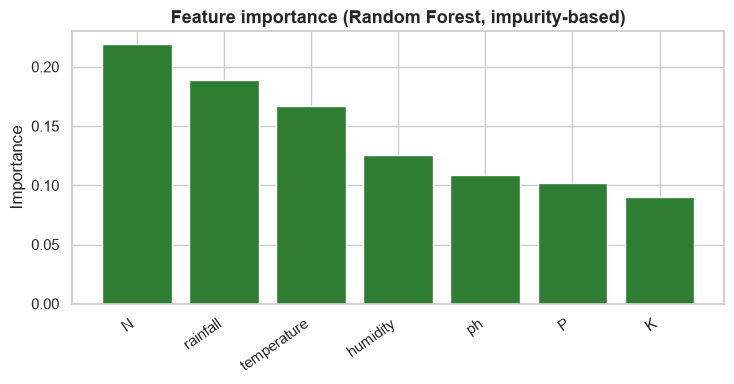

In [11]:
# ---- Test accuracy vs. top-k accuracy ----
order = np.argsort(-test_proba, axis=1, kind="stable")
class_list = list(classes)
true_idx = np.array([class_list.index(c) for c in y_test])
rank_of_true = np.array([int(np.where(order[i] == true_idx[i])[0][0]) + 1 for i in range(len(y_test))])
assert abs((rank_of_true == 1).mean() - metrics["accuracy"]) < 1e-12      # top-1 == test accuracy
assert abs((rank_of_true <= 3).mean() - metrics["top3_accuracy"]) < 1e-12  # top-3 matches sklearn

topk = pd.DataFrame({"k": range(1, len(classes) + 1)})
topk["rows_correct"] = [(rank_of_true <= k).sum() for k in topk["k"]]
topk["accuracy"] = topk["rows_correct"] / len(y_test)
topk["random_guess"] = topk["k"] / len(classes)
topk.to_csv(OUT / "top_k_accuracy.csv", index=False)
display(topk.head(5))

n_top1 = int((rank_of_true == 1).sum()); n_top3 = int((rank_of_true <= 3).sum())
n_miss = len(y_test) - n_top1; n_rescued = n_top3 - n_top1
print(f"Top-1 correct: {n_top1}/{len(y_test)} | top-3 contains the true crop: {n_top3}/{len(y_test)}")
print(f"Of {n_miss} rows where the top choice was wrong, {n_rescued} had the true crop as 2nd or 3rd choice "
      f"and {len(y_test) - n_top3} were missed even by the top three.")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4), gridspec_kw={"width_ratios": [1.1, 1]})
ks = topk["k"][:5]
axes[0].plot(ks, topk["accuracy"][:5], marker="o", color="#2E7D32", lw=2, label="Model")
axes[0].plot(ks, topk["random_guess"][:5], marker="o", color="#9E9E9E", ls="--", label="Random guess (k / 10)")
for k, a in zip(ks, topk["accuracy"][:5]): axes[0].annotate(f"{a:.1%}", (k, a), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
axes[0].set_xticks(list(ks)); axes[0].set_ylim(0, 1.08); axes[0].set_xlabel("k  (true crop is among the k highest-scored)")
axes[0].set_ylabel("Share of test rows"); axes[0].set_title("Accuracy rises with k: the test gets easier")
axes[0].legend(loc="lower right")
rank_counts = pd.Series(np.where(rank_of_true > 3, 4, rank_of_true)).value_counts().reindex([1, 2, 3, 4], fill_value=0)
bars = axes[1].bar(["1st choice\n(= test accuracy)", "2nd choice", "3rd choice", "Not in\ntop 3"], rank_counts.values,
                   color=["#2E7D32", "#81C784", "#C8E6C9", "#E57373"])
axes[1].bar_label(bars, padding=2); axes[1].set_ylabel("Test rows"); axes[1].set_ylim(0, rank_counts.max() * 1.15)
axes[1].set_title("Rank of the true crop (90 test rows)")
plt.tight_layout(); savefig("accuracy_vs_top3.png"); plt.show()

# ---- Feature importance ----
if hasattr(best_model, "feature_importances_"):
    fi = pd.DataFrame({"feature": FEATURES, "importance": best_model.feature_importances_})
    fi = fi.sort_values("importance", ascending=False)
    display(fi); fi.to_csv(OUT / "feature_importance.csv", index=False)
    fig, ax = plt.subplots(figsize=(7.5, 4))
    ax.bar(fi["feature"], fi["importance"], color="#2E7D32"); ax.set_title("Feature importance (Random Forest, impurity-based)")
    ax.set_ylabel("Importance"); plt.xticks(rotation=35, ha="right"); plt.tight_layout()
    savefig("feature_importance.png"); plt.show()

## Task 8 — Test the recommendation function and save deliverables
`recommend_top3` ranks the three highest-scoring crops. A valid number is not necessarily a reliable input, so the notebook also shows the familiarity check that the Streamlit app uses: it compares each input with the range and the combinations the model was fitted on.

In [12]:
from input_checks import build_reference, assess_inputs, overall_level

def recommend_top3(N, P, K, temperature, humidity, ph, rainfall, model=None):
    """Return the three highest-scoring crop classes for supplied soil/climate values."""
    if model is None:
        model = best_model
    values = [float(v) for v in [N, P, K, temperature, humidity, ph, rainfall]]
    if not np.all(np.isfinite(values)):
        raise ValueError("All inputs must be finite numeric values.")
    sample = pd.DataFrame([values], columns=FEATURES)
    probabilities = model.predict_proba(sample)[0]
    order = np.argsort(probabilities)[::-1][:min(3, len(model.classes_))]
    return pd.DataFrame({
        "rank": np.arange(1, len(order) + 1),
        "recommended_crop": model.classes_[order],
        "model_score": probabilities[order]
    })

example = dict(N=60, P=30, K=35, temperature=22, humidity=60, ph=6.4, rainfall=700)
example_top3 = recommend_top3(**example)
display(example_top3.style.format({"model_score": "{:.2%}"}))
example_top3.to_csv(OUT / "example_top3_prediction.csv", index=False)

# Reference = the rows the saved model was fitted on (train + validation).
reference = build_reference(X_trainval, FEATURES)
print("Fitted ranges:"); display(pd.DataFrame(reference["feature_ranges"]).T.round(2))

demo_inputs = {
    "Typical values":                                 dict(example),
    "Temperature -5, rainfall 20 (outside range)":    dict(example, temperature=-5, rainfall=20),
    "Each value ordinary, combination unusual":       dict(N=85, P=20, K=50, temperature=28, humidity=80, ph=5.6, rainfall=300),
}
demo_rows = []
for label, vals in demo_inputs.items():
    top = recommend_top3(**vals)
    found = assess_inputs(vals, reference, X_trainval)
    demo_rows.append({"input": label, "top_crop": top.loc[0, "recommended_crop"],
                      "top_score": f"{top.loc[0, 'model_score']:.0%}",
                      "reliability": overall_level(found),
                      "warnings": "; ".join(f.kind + (f":{f.feature}" if f.feature else "") for f in found) or "none"})
demo_df = pd.DataFrame(demo_rows); display(demo_df)
demo_df.to_csv(OUT / "input_check_examples.csv", index=False)

,rank,recommended_crop,model_score
0,1,teff,56.33%
1,2,wheat,16.67%
2,3,haricot_bean,8.33%


Fitted ranges:


,min,max,p01,p99
N,17.97,96.63,22.19,90.14
P,11.44,60.30,16.29,53.80
K,9.58,63.23,15.00,55.88
temperature,10.31,33.11,12.94,30.41
humidity,22.46,97.18,35.19,89.06
ph,5.10,7.78,5.35,7.35
rainfall,198.16,1742.48,247.79,1587.61


,input,top_crop,top_score,reliability,warnings
0,Typical values,teff,56%,familiar,none
1,"Temperature -5, rainfall 20 (outside range)",barley,55%,unreliable,outside_range:temperature; outside_range:rainfall
2,"Each value ordinary, combination unusual",enset,45%,unreliable,unfamiliar_combination


In [13]:
# How noisy is the check? Held-out test rows are real rows of the same dataset, so they should rarely be flagged.
flag_test = [overall_level(assess_inputs(r.to_dict(), reference, X_trainval)) for _, r in X_test.iterrows()]
rng = np.random.default_rng(RANDOM_STATE)
lo = X_trainval.min(); hi = X_trainval.max()
random_inrange = pd.DataFrame(rng.uniform(lo, hi, size=(500, len(FEATURES))), columns=FEATURES)
flag_rand = [overall_level(assess_inputs(r.to_dict(), reference, X_trainval)) for _, r in random_inrange.iterrows()]
check_validation = pd.DataFrame({
    "test rows (90 held-out real rows)": pd.Series(flag_test).value_counts(),
    "random combinations, each value inside its fitted range (500)": pd.Series(flag_rand).value_counts(),
}).reindex(["familiar", "edge", "unreliable"]).fillna(0).astype(int)
display(check_validation)
check_validation.to_csv(OUT / "input_check_validation.csv")

,test rows (90 held-out real rows),"random combinations, each value inside its fitted range (500)"
familiar,72,48
edge,14,56
unreliable,4,396


In [14]:
# ---- Save deliverables ----
# Model is fitted on train + validation rows, never on the test rows.
joblib.dump(best_model, ROOT / "crop_recommendation_model.joblib")
X_trainval.to_csv(OUT / "model_training_features.csv", index=False)   # fitted rows, used by the app's combination check

metadata = {
    "project": "Crop Recommendation Based on Soil and Climate Conditions",
    "dataset_file": "data/Crop_recommendation_Ethio.csv",
    "dataset_provenance": (
        "Supplied to the group as a 600-row CSV with no documentation of author, collection site, dates, units or "
        "labelling protocol. Statistical structure indicates the rows were synthetically generated, with each label being "
        "the crop a row was generated for rather than a recorded field outcome; this is an inference, not a documented "
        "fact. Not verified Ethiopian field data."),
    "features": FEATURES,
    "target": TARGET,
    "classes": [str(c) for c in classes],
    "selected_model": best_name,
    "random_state": RANDOM_STATE,
    "split": {"train": "70% of rows", "validation": "15% of rows", "test": "15% of rows"},
    "fitted_on": "train + validation rows (510); test rows (90) held out",
    "test_metrics": {k: (float(v) if not isinstance(v, str) else v) for k, v in metrics.items()},
    "input_reference": reference,
    "software": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                 "pandas": pd.__version__, "numpy": np.__version__},
}
with open(ROOT / "model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

# Colab convenience: bundle everything and download it.
if IN_COLAB:
    with zipfile.ZipFile("crop_recommendation_outputs.zip", "w", zipfile.ZIP_DEFLATED) as z:
        for name in ["crop_recommendation_model.joblib", "model_metadata.json", "input_checks.py"]:
            z.write(name)
        for p in OUT.rglob("*"):
            if p.is_file():
                z.write(p, arcname=str(p.relative_to(ROOT)))
    from google.colab import files
    files.download("crop_recommendation_outputs.zip")
print("Saved model, metadata and", len(list(OUT.iterdir())), "files in outputs/")

Saved model, metadata and 24 files in outputs/
